# HU-4 · EDA medicamentos esquizofrenia

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

RUTA=Path(("data/hu3_esquizofrenia.xlsx"))
df_HU3=pd.read_excel(RUTA)
pd.set_option('display.max_rows', None)
pd.set_option("display.max_info_columns", 200)
pd.set_option("display.max_info_rows", 100_000)

df_eda=df_HU3.copy()

FECHA_REFERENCIA=pd.Timestamp("2026-09-27") #fecha de descarga de los datos

identificadores=["nregistro","cn","nombre","url_ficha_tecnica","url_foto_materiales"]

categoricas = ["pactivos", "labtitular", "labcomercializador", "dosis", "forma_farmaceutica_simplificada", "vias_administracion", "Estado"]

binarias = ["comercializado", "requiere_receta", "generico", "afecta_conduccion", "triangulo_negro", "medicamento_huerfano", "biosimilar"]

numericas = ["num_registros_atc", "num_principios_activos", "num_excipientes", "palabras_seccion_4_4", "num_tablas", "num_grave", "Precio venta al público con IVA", "Precio de referencia"]

fechas = ["estado_aut", "estado_rev"]

si_no = ["Tratamiento de larga duración", "Especial control médico"]

## 1. Visión general

In [2]:
shape= df_eda.shape
print("Filas y columnas", shape)

Filas y columnas (1013, 31)


In [3]:
pd.set_option('display.max_columns', None)
df_eda.head()

,nregistro,nombre,pactivos,labtitular,labcomercializador,cn,dosis,forma_farmaceutica_simplificada,estado_aut,estado_rev,vias_administracion,comercializado,requiere_receta,generico,afecta_conduccion,triangulo_negro,medicamento_huerfano,biosimilar,url_ficha_tecnica,url_foto_materiales,num_registros_atc,num_principios_activos,num_excipientes,palabras_seccion_4_4,num_tablas,num_grave,Estado,Precio venta al público con IVA,Precio de referencia,Tratamiento de larga duración,Especial control médico
0,113823002,"ADASUVE 9,1 MG POLVO PARA INHALACION (UNIDOSIS)",LOXAPINA,Ferrer Internacional S.A.,Ferrer Farma S.A.,606711,"9,1 MG",INHALACIÓN PULMONAR,2016-02-15,NaN,VÍA INHALATORIA,1,1,0,1,0,0,0,https://cima.aemps.es/cima/dochtml/ft/113823002/FT_113823002.html,https://cima.aemps.es/cima/fotos/thumbnails/materialas/113823002/113823002_materialas.jpg,3,1,0,833,2,5,NaN,NaN,NaN,NaN,NaN
1,69796,AMISULPRIDA NORMON 100 MG COMPRIMIDOS RECUBIERTOS CON PELICULA EFG,AMISULPRIDA,Laboratorios Normon S.A.,Laboratorios Normon S.A.,660954,100 mg amisulprida,COMPRIMIDO,2008-05-05,NaN,VÍA ORAL,1,1,1,1,0,0,0,https://cima.aemps.es/cima/dochtml/ft/69796/FT_69796.html,https://cima.aemps.es/cima/fotos/thumbnails/materialas/69796/69796_materialas.jpg,3,1,2,945,0,3,ALTA,19.94,19.94,NO,NO
2,69797,AMISULPRIDA NORMON 200 MG COMPRIMIDOS RECUBIERTOS CON PELICULA EFG,AMISULPRIDA,Laboratorios Normon S.A.,Laboratorios Normon S.A.,660955,200 mg amisulprida,COMPRIMIDO,2008-05-05,NaN,VÍA ORAL,1,1,1,1,0,0,0,https://cima.aemps.es/cima/dochtml/ft/69797/FT_69797.html,https://cima.aemps.es/cima/fotos/thumbnails/materialas/69797/69797_materialas.jpg,3,1,2,945,0,3,ALTA,39.87,39.87,NO,NO
3,69798,AMISULPRIDA NORMON 400 MG COMPRIMIDOS RECUBIERTOS CON PELICULA EFG,AMISULPRIDA,Laboratorios Normon S.A.,Laboratorios Normon S.A.,660956,400 mg amisulprida,COMPRIMIDO,2008-05-05,NaN,VÍA ORAL,1,1,1,1,0,0,0,https://cima.aemps.es/cima/dochtml/ft/69798/FT_69798.html,https://cima.aemps.es/cima/fotos/thumbnails/materialas/69798/69798_materialas.jpg,3,1,2,945,0,3,ALTA,39.87,39.87,NO,NO
4,80788,ARIPIPRAZOL CINFA 1 MG/ML SOLUCION ORAL EFG,ARIPIPRAZOL,Laboratorios Cinfa S.A.,Laboratorios Cinfa S.A.,710789,1 mg/ml,SOLUCIÓN/SUSPENSIÓN ORAL,2016-05-03,NaN,VÍA ORAL,1,1,1,1,0,0,0,https://cima.aemps.es/cima/dochtml/ft/80788/FT_80788.html,https://cima.aemps.es/cima/fotos/thumbnails/materialas/80788/80788_materialas.jpg,3,1,3,1611,1,9,ALTA,25.27,25.27,NO,NO


In [4]:
df_eda.dtypes

,0
nregistro,int64
nombre,str
pactivos,str
labtitular,str
labcomercializador,str
cn,int64
dosis,str
forma_farmaceutica_simplificada,str
estado_aut,str
estado_rev,str


El dataset tiene 1013 medicamentos y 31 columnas. Al revisar los tipos vemos que:
- Las fechas (`estado_aut`, `estado_rev`) están como texto, hay que pasarlas a datetime para poder calcular la antigüedad, que puede ser una variable útil para el modelo de la HU-5.
- `dosis` es texto con la unidad incluida ("10 mg"), habría que quitar las unidades y pasarla a float.
- `Tratamiento de larga duración` y `Especial control médico` están como texto (Sí/No). Lo vemos en el apartado 4.

In [5]:
print(df_eda[fechas].dtypes)
for col in ["estado_aut", "estado_rev"]:
    df_eda[col] = pd.to_datetime(df_eda[col], format="%Y-%m-%d", errors="coerce")

print(df_eda[fechas].dtypes)

estado_aut    str
estado_rev    str
dtype: object
estado_aut    datetime64[us]
estado_rev    datetime64[us]
dtype: object


In [6]:
df_eda.info()

<class 'pandas.DataFrame'>
RangeIndex: 1013 entries, 0 to 1012
Data columns (total 31 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   nregistro                        1013 non-null   int64         
 1   nombre                           1013 non-null   str           
 2   pactivos                         1013 non-null   str           
 3   labtitular                       1013 non-null   str           
 4   labcomercializador               1010 non-null   str           
 5   cn                               1013 non-null   int64         
 6   dosis                            1013 non-null   str           
 7   forma_farmaceutica_simplificada  1013 non-null   str           
 8   estado_aut                       1013 non-null   datetime64[us]
 9   estado_rev                       145 non-null    datetime64[us]
 10  vias_administracion              1013 non-null   str           
 11  co

In [7]:
df_eda.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
nregistro,1013.0,NaN,NaN,NaN,44034542.967423,19622.0,72374.0,79950.0,86753.0,1241795006.0,210117533.751365
nombre,1013,996,"ADASUVE 9,1 MG POLVO PARA INHALACION (UNIDOSIS)",2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pactivos,1013,32,OLANZAPINA,225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
labtitular,1013,75,Teva Pharma S.L.U.,62,NaN,NaN,NaN,NaN,NaN,NaN,NaN
labcomercializador,1010,66,Teva Pharma S.L.U.,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cn,1013.0,NaN,NaN,NaN,704884.16387,603234.0,672594.0,705989.0,727177.0,989608.0,46902.730694
dosis,1013,134,10 mg,103,NaN,NaN,NaN,NaN,NaN,NaN,NaN
forma_farmaceutica_simplificada,1013,8,COMPRIMIDO,533,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado_aut,1013,NaN,NaN,NaN,2013-11-19 16:08:03.316880,1953-06-30 00:00:00,2009-10-19 00:00:00,2015-01-30 00:00:00,2018-12-21 00:00:00,2026-08-04 00:00:00,NaN
estado_rev,145,NaN,NaN,NaN,2024-10-17 21:50:53.793103,2021-10-05 00:00:00,2023-09-21 00:00:00,2025-03-07 00:00:00,2026-02-09 00:00:00,2026-09-16 00:00:00,NaN


## 2. Identificadores y duplicados

In [8]:
resumen_ids = pd.DataFrame({
    "nulos": df_eda[identificadores].isna().sum(),
    "unicos": df_eda[identificadores].nunique(),
    "duplicados": {c: df_eda[c].dropna().duplicated().sum() for c in identificadores},
})
resumen_ids

,nulos,unicos,duplicados
nregistro,0,1013,0
cn,0,1013,0
nombre,0,996,17
url_ficha_tecnica,0,1013,0
url_foto_materiales,780,233,0


In [9]:
duplicados=df_eda[df_eda["nombre"].duplicated(keep=False)].sort_values("nombre")
duplicados[["nombre", "nregistro", "cn", "labtitular", "comercializado"]].head(10)

,nombre,nregistro,cn,labtitular,comercializado
245,ABILIFY 1 MG/ML SOLUCION ORAL,4276034,652738,Otsuka Pharmaceutical Netherlands B.V.,1
246,ABILIFY 1 MG/ML SOLUCION ORAL,4276035,652739,Otsuka Pharmaceutical Netherlands B.V.,0
239,ABILIFY MAINTENA 300 MG POLVO Y DISOLVENTE PARA SUSPENSION INYECTABLE DE LIBERACION PROLONGADA,113882001,701735,Otsuka Pharmaceutical Netherlands B.V.,1
240,ABILIFY MAINTENA 300 MG POLVO Y DISOLVENTE PARA SUSPENSION INYECTABLE DE LIBERACION PROLONGADA,113882003,701737,Otsuka Pharmaceutical Netherlands B.V.,0
242,ABILIFY MAINTENA 400 MG POLVO Y DISOLVENTE PARA SUSPENSION INYECTABLE DE LIBERACION PROLONGADA,113882004,701738,Otsuka Pharmaceutical Netherlands B.V.,0
241,ABILIFY MAINTENA 400 MG POLVO Y DISOLVENTE PARA SUSPENSION INYECTABLE DE LIBERACION PROLONGADA,113882002,701736,Otsuka Pharmaceutical Netherlands B.V.,1
262,"ADASUVE 9,1 MG POLVO PARA INHALACION (UNIDOSIS)",113823004,698230,Ferrer Internacional S.A.,0
0,"ADASUVE 9,1 MG POLVO PARA INHALACION (UNIDOSIS)",113823002,606711,Ferrer Internacional S.A.,1
44,INVEGA 3 mg COMPRIMIDOS DE LIBERACION PROLONGADA,7395001,663333,Janssen-Cilag International N.V,0
455,INVEGA 3 mg COMPRIMIDOS DE LIBERACION PROLONGADA,7395004,659840,Janssen-Cilag International N.V,0


In [10]:
print("Nombres repetidos:", duplicados["nombre"].nunique())
print("Con distinto laboratorio titular:", (duplicados.groupby("nombre")["labtitular"].nunique()>1).sum())
print("Uno comercializado y otro no:", (duplicados.groupby("nombre")["comercializado"].nunique()>1).sum())

Nombres repetidos: 17
Con distinto laboratorio titular: 0
Uno comercializado y otro no: 7


`nregistro`, `cn` y `url_ficha_tecnica` son únicos y no tienen nulos. Salvo la url de las fotos de los materiales (780 nulos), ningún identificador tiene entradas vacías, lo cual es esperable ya que la foto no es obligatoria.

Hay 17 nombres repetidos aunque todos los cn sean únicos. Al mirarlos vemos que no es porque cambie el laboratorio (en todos es el mismo), sino porque son medicamentos de autorización europea (Abilify, Abilify Maintena...): la EMA da un número a cada presentación y CIMA lo convierte en un `nregistro` distinto. En 7 de ellos una presentación está comercializada y la otra no, así que si quitamos duplicados hay que quedarse con la comercializada. En el K-Means estos duplicados pesarían el doble.

Como identificador nos quedamos solo con `nregistro`, que identifica el medicamento y nos sirve para cruzar los clusters con el dataset original después del modelo (no entra en el K-Means). `cn` es solo un envase (en la HU-1 cogimos el primero) y únicamente lo necesitábamos para cruzar con el Nomenclátor. El resto de identificadores se eliminan.

## 3. Variables constantes

In [11]:
for col in ["requiere_receta", "afecta_conduccion", "triangulo_negro", "medicamento_huerfano", "biosimilar", "num_principios_activos", "num_registros_atc"]:
    print(df_eda[col].value_counts(dropna=False), "\n")

requiere_receta
1    1013
Name: count, dtype: int64 

afecta_conduccion
1    1012
0       1
Name: count, dtype: int64 

triangulo_negro
0    1013
Name: count, dtype: int64 

medicamento_huerfano
0    1013
Name: count, dtype: int64 

biosimilar
0    1013
Name: count, dtype: int64 

num_principios_activos
1    1008
2       5
Name: count, dtype: int64 

num_registros_atc
3    1007
2       6
Name: count, dtype: int64 



In [12]:
df_eda[df_eda["num_registros_atc"]!=3][["nombre", "pactivos", "num_registros_atc"]]

,nombre,pactivos,num_registros_atc
122,QUETIAPINA CINFA 300 mg COMPRIMIDOS DE LIBERACION PROLONGADA EFG,QUETIAPINA FUMARATO,2
124,QUETIAPINA CINFA 400 mg COMPRIMIDOS DE LIBERACION PROLONGADA EFG,QUETIAPINA FUMARATO,2
420,ATROLAK PROLONG 200 MG COMPRIMIDOS DE LIBERACION PROLONGADA EFG,QUETIAPINA HEMIFUMARATO,2
421,ATROLAK PROLONG 300 MG COMPRIMIDOS DE LIBERACION PROLONGADA EFG,QUETIAPINA HEMIFUMARATO,2
422,ATROLAK PROLONG 400MG COMPRIMIDOS DE LIBERACION PROLONGADA EFG,QUETIAPINA HEMIFUMARATO,2
714,QUETIAPINA CINFA 200 mg COMPRIMIDOS DE LIBERACION PROLONGADA EFG,QUETIAPINA FUMARATO,2


Hay varias variables que son constantes o prácticamente constantes, por lo que no aportan nada al K-Means de la HU-5 y se eliminan en la limpieza:

- `requiere_receta`: 1 en todos, todos los antipsicóticos necesitan receta.
- `afecta_conduccion`: 1 en todos menos uno, por el efecto sedante de estos medicamentos.
- `medicamento_huerfano`: siempre 0, un medicamento huérfano es el que trata una enfermedad rara y la esquizofrenia no lo es (afecta a cerca del 1 % de la población).
- `biosimilar`: siempre 0, un biosimilar es la copia de un medicamento biológico y los antipsicóticos son moléculas químicas, por eso sus copias son genéricos.
- `triangulo_negro`: siempre 0, el triángulo negro indica seguimiento adicional (principios activos nuevos) y los nuestros llevan años en el mercado.
- `num_principios_activos`: casi siempre 1, solo vale 2 en algunos packs de paliperidona.
- `num_registros_atc`: casi siempre 3. No es el número de medicamentos, sino cuántos niveles del código ATC guarda CIMA para cada uno. Los 6 que tienen 2 son quetiapina de liberación prolongada a los que les falta un nivel.
- `Tratamiento de larga duración` y `Especial control médico`: solo "NO" o nulo (apartado 4).

## 4. Variables del Nomenclátor

In [13]:
df_eda["Tratamiento de larga duración"].value_counts(dropna=False)

,count
Tratamiento de larga duración,
NO,727
NaN,286


In [14]:
df_eda["Especial control médico"].value_counts(dropna=False)

,count
Especial control médico,
NO,727
NaN,286


In [15]:
nomenclator=pd.read_csv("data/20260927_Nomenclator_de_Facturacion.csv")
nomenclator["Tratamiento de larga duración"].value_counts(dropna=False)

,count
Tratamiento de larga duración,
NO,13887
NaN,4776
SI,1884


In [16]:
#todas las presentaciones del nomenclator con nuestros principios activos
pa_nomenclator=nomenclator["Principio activo o asociación de principios activos"].str.upper()
nuestros=nomenclator[pa_nomenclator.isin(df_eda["pactivos"].str.upper().unique())]
print("Presentaciones:", len(nuestros))
print(nuestros["Tratamiento de larga duración"].value_counts(dropna=False))
print(nuestros["Aportación del beneficiario"].value_counts(dropna=False))

Presentaciones: 1097
Tratamiento de larga duración
NO    1097
Name: count, dtype: int64
Aportación del beneficiario
ESPECIAL    1045
NORMAL        52
Name: count, dtype: int64


### Variables del Nomenclátor: Tratamiento de larga duración y Especial control médico

Estas dos variables vienen del cruce con el Nomenclátor del Ministerio de Sanidad (HU-3) y están como texto. Al ser indicadores Sí/No nos planteamos pasarlas a binarias, pero con `value_counts(dropna=False)` vemos que ninguna toma el valor "SI": solo aparece "NO" (727) y nulo (286), los mismos en las dos.

- *Especial control médico:* esta clasificación se eliminó con el Real Decreto 717/2019, por lo que hoy ningún medicamento la tiene, ni siquiera la clozapina, que antes sí estaba sometida a especial control médico.
- *Tratamiento de larga duración:* comprobamos en el CSV del Nomenclátor que no es un fallo de la descarga ni del cruce. En el fichero sí hay medicamentos con "SI", pero ninguna de las presentaciones con nuestros principios activos lo tiene, con ningún envase. Lo que sí tienen es la aportación del beneficiario "ESPECIAL" (reducida), que es lo que se aplica a los tratamientos crónicos. Las únicas con aportación "NORMAL" son las de diazepam.

**Conclusión:** `Especial control médico` se elimina. Con `Tratamiento de larga duración` haremos la prueba que propuso el profesor: convertir los nulos en "UNKNOWN" y comparar el modelo con y sin esta variable (ver apartado 6).

## 5. Fechas

In [17]:
antiguedad=(FECHA_REFERENCIA-df_eda["estado_aut"]).dt.days/365.25
antiguedad.describe()

,estado_aut
count,1013.000000
mean,12.852369
std,8.572415
min,0.147844
25%,7.767283
50%,11.657769
75%,16.939083
max,73.242984


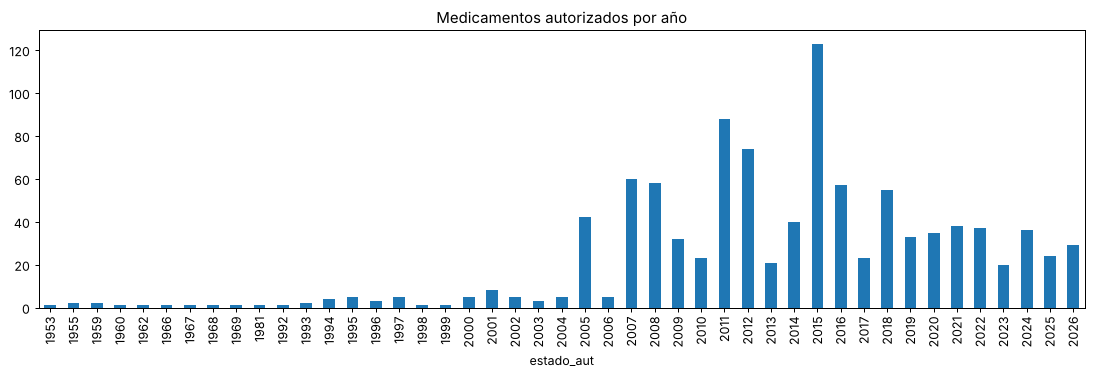

In [18]:
df_eda["estado_aut"].dt.year.value_counts().sort_index().plot(kind="bar", figsize=(15, 4))
plt.title("Medicamentos autorizados por año")
plt.show()

In [19]:
periodo=pd.cut(df_eda["estado_aut"].dt.year, bins=[1900, 1999, 2004, 2019, 2024, 2026], labels=["antes de 2000", "2000-2004", "2005-2019", "2020-2024", "2025-2026"])
df_eda.groupby(periodo)["comercializado"].mean()

,comercializado
estado_aut,
antes de 2000,1.000000
2000-2004,0.884615
2005-2019,0.771117
2020-2024,0.608434
2025-2026,0.132075


In [20]:
pd.crosstab(
    df_eda["estado_rev"].notna().rename("tiene_estado_rev"),
    df_eda["comercializado"],
    margins=True,
)

comercializado,0,1,All
tiene_estado_rev,,,
False,137,731,868
True,145,0,145
All,282,731,1013


In [21]:
print(df_eda["estado_rev"].dt.year.value_counts().sort_index())
print("Genéricos revocados:", df_eda[df_eda["estado_rev"].notna()]["generico"].sum())

estado_rev
2021.0     2
2022.0    21
2023.0    21
2024.0    25
2025.0    28
2026.0    48
Name: count, dtype: int64
Genéricos revocados: 141


**estado_aut (fecha de autorización):** no tiene nulos y va de 1953 (Largactil, el primer antipsicótico) a 2026. La mitad de los medicamentos tiene menos de 11,7 años. Los picos de 2005, 2007-2008, 2011-2012 y 2015 coinciden con la llegada de los genéricos cuando caducaron las patentes de olanzapina, risperidona, quetiapina y aripiprazol.

La antigüedad está relacionada con estar comercializado: se venden todos los autorizados antes de 2000, pero solo el 13 % de los autorizados en 2025-2026, porque muchos se autorizan antes de lanzarse. Por eso creamos `antiguedad_anios` usando una fecha de referencia fija (27/09/2026, la de la descarga) y eliminamos la fecha.

**estado_rev:** no es la fecha de revisión sino la de **revocación** (en la API de CIMA el estado tiene `aut`, `susp` y `rev`). Lo confirma la tabla: ningún medicamento con esta fecha está comercializado (0 de 145). Por tanto el 86 % de nulos no es que falte el dato, sino que el medicamento no está revocado. La fecha en sí no aporta nada (todos los revocados están sin comercializar sea cual sea el año, y casi todos son genéricos, 141 de 145), pero sí sirve saber si está revocado, porque separa los 282 no comercializados en 145 revocados y 137 que siguen autorizados pero no se venden. Creamos `revocado` (0/1) y eliminamos la fecha.

## 6. Valores nulos

In [22]:
nulos=pd.DataFrame({
    "n_nulos":df_eda.isna().sum(),
    "porcentaje_nulos": df_eda.isna().sum()/shape[0]
})

nulos[nulos["n_nulos"]>0].sort_values("porcentaje_nulos", ascending=False)

,n_nulos,porcentaje_nulos
estado_rev,868,0.856861
url_foto_materiales,780,0.769990
Precio de referencia,322,0.317868
Estado,286,0.282330
Tratamiento de larga duración,286,0.282330
Precio venta al público con IVA,286,0.282330
Especial control médico,286,0.282330
labcomercializador,3,0.002962


In [23]:
pd.crosstab(
    df_eda["comercializado"],
    df_eda["Tratamiento de larga duración"].isna().rename("TLD_nulo"),
    margins=True,
)

TLD_nulo,False,True,All
comercializado,,,
0,100,182,282
1,627,104,731
All,727,286,1013


In [24]:
pd.crosstab(
    df_eda["comercializado"],
    df_eda["Especial control médico"].isna().rename("ECM_nulo"),
    margins=True,
)

ECM_nulo,False,True,All
comercializado,,,
0,100,182,282
1,627,104,731
All,727,286,1013


In [25]:
df_eda[(df_eda["comercializado"]==0) & (df_eda["Estado"].notna())]["Estado"].value_counts()

,count
Estado,
BAJA GENERAL,67
BAJA POR NO COMERCIALIZAR,23
SUSPENSION TEMPORAL GENERAL,9
ALTA,1


In [26]:
df_eda[df_eda["labcomercializador"].isna()][
    ["nregistro", "nombre", "labtitular", "labcomercializador", "comercializado", "Estado"]
]

,nregistro,nombre,labtitular,labcomercializador,comercializado,Estado
397,1151009007,ARIPIPRAZOL ZENTIVA 10 MG COMPRIMIDOS EFG,Zentiva K.S.,NaN,0,NaN
398,1151009012,ARIPIPRAZOL ZENTIVA 15 MG COMPRIMIDOS EFG,Zentiva K.S.,NaN,0,NaN
399,1151009002,ARIPIPRAZOL ZENTIVA 5 MG COMPRIMIDOS EFG,Zentiva K.S.,NaN,0,NaN


- `estado_rev` (86 %): no es un dato que falte, significa que el medicamento no está revocado (apartado 5).
- `url_foto_materiales` (77 %): no es un campo obligatorio, y además es un identificador que se elimina.
- `Estado`, `Precio venta al público con IVA`, `Tratamiento de larga duración` y `Especial control médico` (286, 28 %): quedan vacías a la vez porque el cn del medicamento no se encontró en el Nomenclátor al hacer el cruce.
- `Precio de referencia` (322): los mismos 286 más 36 que no tienen precio de referencia asignado.
- `labcomercializador` (3): son las tres dosis de Aripiprazol Zentiva, que no están comercializadas. El laboratorio viene en el nombre, así que se rellenan con "Zentiva K.S.".

**Nulos del Nomenclátor y medicamentos comercializados.** Aunque los totales se parecen (727 con dato y 731 comercializados), la tabla cruzada muestra que no son los mismos medicamentos:
- 104 comercializados no tienen dato, porque en la HU-1 cogimos solo el primer cn y ese envase concreto puede no estar en el Nomenclátor aunque el medicamento se venda con otro.
- 100 no comercializados sí tienen dato, porque el Nomenclátor guarda los dados de baja (99 aparecen como BAJA GENERAL, BAJA POR NO COMERCIALIZAR o SUSPENSIÓN TEMPORAL).

Por eso, tener dato del Nomenclátor acierta en torno al 80 % si un medicamento está comercializado, pero no es lo mismo. Para la prueba del profesor, los nulos de `Tratamiento de larga duración` pasan a "UNKNOWN" (variable `tld_unknown`, 0/1). `Especial control médico` y la columna `Estado_nan` del one-hot darían exactamente la misma columna, así que solo usamos una.

## 7. Precio

In [27]:
df_eda[["Precio venta al público con IVA", "Precio de referencia"]].corr()

,Precio venta al público con IVA,Precio de referencia
Precio venta al público con IVA,1.0,1.0
Precio de referencia,1.0,1.0


In [28]:
df_eda.groupby("forma_farmaceutica_simplificada")["Precio venta al público con IVA"].median()

,Precio venta al público con IVA
forma_farmaceutica_simplificada,
CAPSULA,68.21
COMPRIMIDO,32.41
COMPRIMIDO BUCODISPERSABLE/LIOTAB,52.89
COMPRIMIDO LIBERACION MODIFICADA,64.82
INHALACIÓN PULMONAR,NaN
INYECTABLE,152.41
SOLUCION/SUSPENSION GOTAS ORALES,3.65
SOLUCIÓN/SUSPENSIÓN ORAL,13.66


In [29]:
#unificamos las sales quedandonos con la primera palabra (QUETIAPINA FUMARATO -> QUETIAPINA)
pa_base=df_eda["pactivos"].str.split().str[0].str.replace(",", "")
print("Principios activos:", df_eda["pactivos"].nunique(), "->", pa_base.nunique())

precio=df_eda["Precio venta al público con IVA"]
mediana=precio.groupby([pa_base, df_eda["forma_farmaceutica_simplificada"]]).transform("median")
print("Nulos que se rellenan por principio activo y forma:", (precio.isna() & mediana.notna()).sum())
df_eda[precio.isna() & mediana.isna()][["nombre", "pactivos", "forma_farmaceutica_simplificada"]]

Principios activos: 32 -> 20
Nulos que se rellenan por principio activo y forma: 282


,nombre,pactivos,forma_farmaceutica_simplificada
0,"ADASUVE 9,1 MG POLVO PARA INHALACION (UNIDOSIS)",LOXAPINA,INHALACIÓN PULMONAR
262,"ADASUVE 9,1 MG POLVO PARA INHALACION (UNIDOSIS)",LOXAPINA,INHALACIÓN PULMONAR
444,DIAZEPAM ARISTO 10 MG COMPRIMIDOS EFG,DIAZEPAM,COMPRIMIDO
445,DIAZEPAM ARISTO 5 MG COMPRIMIDOS EFG,DIAZEPAM,COMPRIMIDO


El PVP y el precio de referencia tienen correlación 1, son prácticamente la misma variable, así que nos quedamos con una. Elegimos el **PVP con IVA** porque tiene menos nulos (286 frente a 322).

El precio cambia mucho según la forma farmacéutica (los inyectables están en torno a 152 € y los comprimidos en 32 €), por lo que no tiene sentido rellenar con una única mediana. Rellenamos los nulos con la **mediana del mismo principio activo y la misma forma farmacéutica**, unificando antes las sales (de 32 principios activos pasamos a 20). Así se rellenan 282 de los 286. Los 4 que quedan son 2 de diazepam (se rellenan con la mediana de comprimidos) y 2 de Adasuve, que es inhalado y no hay ningún inhalado con precio, así que se rellenan con la mediana general.

## 8. Dosis

In [30]:
print("Valores distintos:", df_eda["dosis"].nunique())
df_eda["dosis"].value_counts().head(10)

Valores distintos: 134


,count
dosis,
10 mg,103
5 mg,84
15 mg,64
200 mg,62
300 mg,54
50 mg,53
100 mg,46
150 mg,39
400 mg,39


In [31]:
dosis=df_eda["dosis"].str.lower().str.replace(",", ".")
dosis[dosis.str.contains("/|%|\\+|desconocida")].unique()

<StringArray>
[                   '1 mg/ml',        '15.00 mg/comprimido',
        '20.00 mg/comprimido',         '40 mg/cápsula dura',
         '60 mg/cápsula dura',           '150 mg + 100  mg',
             '100 mg +150 mg',                    '2 mg/ml',
 '200 mg haloperidol/ 100 ml',                   '25 mg/ml',
     '40 mg clorpromazina/ml',      '5 mg clorpromazina/ml',
             '100 mg /150 mg',            '100 mg + 150 mg',
            '150 mg + 100 mg',                   '20 mg/ml',
  '25 mg levomepromazina/ ml',        '4 % levomepromazina',
     '100 mg amisulprida/ ml',                'desconocida']
Length: 20, dtype: str

In [32]:
dosis_mg=dosis.str.extract(r"(\d+(?:\.\d+)?)\s*mg")[0].astype(float)
print("Nulos:", dosis_mg.isna().sum())
print("En mg/ml o %:", dosis.str.contains("ml|%").sum())
dosis_mg.describe()

Nulos: 3
En mg/ml o %: 31


,0
count,1010.00000
mean,77.14828
std,121.49607
min,0.50000
25%,6.00000
50%,15.00000
75%,100.00000
max,1000.00000


`dosis` tiene 134 valores distintos en texto, así no es analizable directamente. La mayoría son del tipo "10 mg", así que quitamos las unidades y la pasamos a float (`dosis_mg`). Hay algunos casos especiales:
- Las soluciones e inyectables vienen en mg/ml (31 registros), que no se puede comparar con los mg de un comprimido. Los marcamos con una variable `dosis_es_concentracion` (0/1).
- Al extraer el número salen 3 nulos y hay un valor mal leído, que se corrigen a mano: "4 % levomepromazina" (40 mg/ml), "Desconocida" (Zyprexa 10 mg, viene en el nombre) y "200 mg haloperidol/ 100 ml" (que en realidad son 2 mg/ml).
- Los packs de paliperidona ("100 mg + 150 mg") están pendientes de decidir si se suman, se coge el máximo o el primero.

La dosis va de 0,5 a 1000 mg (los más altos son inyectables de liberación prolongada) y depende mucho del principio activo: 400 mg de quetiapina son más o menos como 20 mg de olanzapina.

## 9. Variables numéricas

In [33]:
df_eda[numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
num_registros_atc,1013.0,2.994077,0.076771,2.00,3.00,3.00,3.00,3.00
num_principios_activos,1013.0,1.004936,0.070117,1.00,1.00,1.00,1.00,2.00
num_excipientes,1013.0,2.122409,1.315318,0.00,1.00,2.00,3.00,10.00
palabras_seccion_4_4,1013.0,2001.996051,759.104511,0.00,1455.00,1759.00,2709.00,3791.00
num_tablas,1013.0,2.651530,2.391105,0.00,1.00,2.00,3.00,21.00
num_grave,1013.0,8.257651,6.253201,0.00,4.00,6.00,15.00,21.00
Precio venta al público con IVA,727.0,66.391197,94.215658,1.51,24.59,48.61,79.33,1467.94
Precio de referencia,691.0,64.186860,87.077234,2.26,25.27,52.89,79.33,1467.94


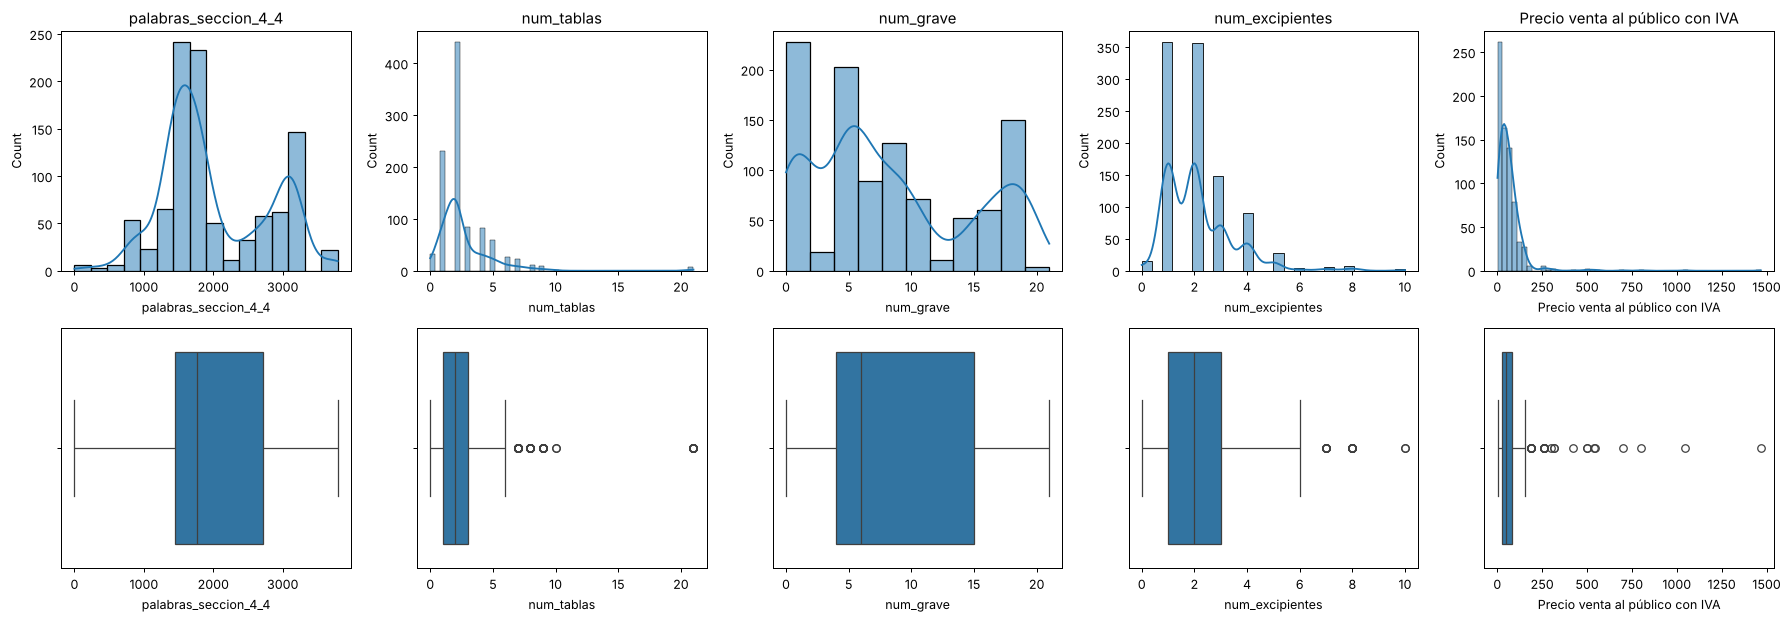

In [34]:
num_cols = ["palabras_seccion_4_4", "num_tablas", "num_grave", "num_excipientes",
            "Precio venta al público con IVA"]

fig, axes = plt.subplots(2, len(num_cols), figsize=(20, 7))
for i, col in enumerate(num_cols):
    sns.histplot(df_eda[col].dropna(), ax=axes[0, i], kde=True)
    sns.boxplot(x=df_eda[col].dropna(), ax=axes[1, i])
    axes[0, i].set_title(col)
plt.tight_layout()
plt.show()

In [35]:
df_eda.groupby(pa_base)[["palabras_seccion_4_4", "num_grave", "num_tablas"]].mean().round(0).sort_values("palabras_seccion_4_4")

,palabras_seccion_4_4,num_grave,num_tablas
pactivos,,,
DIAZEPAM,541.0,7.0,0.0
ZUCLOPENTIXOL,687.0,0.0,1.0
CLOTIAPINA,755.0,4.0,1.0
ZIPRASIDONA,805.0,6.0,1.0
LOXAPINA,833.0,5.0,2.0
LURASIDONA,877.0,6.0,5.0
CARIPRAZINA,959.0,10.0,4.0
SULPIRIDA,1011.0,5.0,0.0
AMISULPRIDA,1026.0,3.0,0.0


- `palabras_seccion_4_4` y `num_grave` tienen varios picos en vez de una campana. Al agrupar por principio activo vemos el motivo: los genéricos copian la ficha técnica del original, así que cada principio activo tiene casi siempre los mismos valores. Por ejemplo la olanzapina tiene 1 mención de "grave" y la quetiapina unas 17, con unas 3000 palabras en la sección 4.4.
- `num_tablas` tiene la mediana en 2 y una cola hacia la derecha (máximo 21).
- `num_excipientes` tiene la mediana en 2; los que tienen 7-10 son soluciones orales e inyectables, que llevan conservantes.
- El precio tiene mucha cola a la derecha (mediana de unos 49 € y máximo de 1468 €), los más caros son inyectables de liberación prolongada.

Los outliers no los tratamos, todas las variables entran con sus valores. Para que los extremos no deformen la escala usaremos `RobustScaler`, que usa la mediana. Hay que tener en cuenta que como estas variables siguen al principio activo, es probable que el K-Means acabe agrupando sobre todo por principio activo.

## 10. Variables categóricas

In [36]:
df_eda[categoricas].describe()

,pactivos,labtitular,labcomercializador,dosis,forma_farmaceutica_simplificada,vias_administracion,Estado
count,1013,1013,1010,1013,1013,1013,727
unique,32,75,66,134,8,4,4
top,OLANZAPINA,Teva Pharma S.L.U.,Teva Pharma S.L.U.,10 mg,COMPRIMIDO,VÍA ORAL,ALTA
freq,225,62,80,103,533,926,624


In [37]:
print(df_eda["forma_farmaceutica_simplificada"].value_counts(), "\n")
print(df_eda["vias_administracion"].value_counts(), "\n")
print(df_eda["Estado"].value_counts(dropna=False))

forma_farmaceutica_simplificada
COMPRIMIDO                           533
COMPRIMIDO LIBERACION MODIFICADA     168
COMPRIMIDO BUCODISPERSABLE/LIOTAB    143
INYECTABLE                            85
CAPSULA                               50
SOLUCIÓN/SUSPENSIÓN ORAL              28
SOLUCION/SUSPENSION GOTAS ORALES       4
INHALACIÓN PULMONAR                    2
Name: count, dtype: int64 

vias_administracion
VÍA ORAL                              926
VÍA INTRAMUSCULAR                      84
VÍA INHALATORIA                         2
VÍA INTRAMUSCULAR, VÍA INTRAVENOSA      1
Name: count, dtype: int64 

Estado
ALTA                           624
NaN                            286
BAJA GENERAL                    68
BAJA POR NO COMERCIALIZAR       26
SUSPENSION TEMPORAL GENERAL      9
Name: count, dtype: int64


In [38]:
pa_base.value_counts()

,count
pactivos,
QUETIAPINA,266
OLANZAPINA,225
ARIPIPRAZOL,215
RISPERIDONA,97
PALIPERIDONA,90
ZIPRASIDONA,29
CLOZAPINA,23
LURASIDONA,17
AMISULPRIDA,15


In [39]:
lab=df_eda["labcomercializador"].fillna("Zentiva K.S.").value_counts()
print("Laboratorios con 30 o más medicamentos:", (lab>=30).sum())
print("Filas que irían a OTROS:", lab[lab<30].sum())
print("Principios activos con 10 o más:", (pa_base.value_counts()>=10).sum())

Laboratorios con 30 o más medicamentos: 12
Filas que irían a OTROS: 440
Principios activos con 10 o más: 9


In [40]:
print("Mismo titular y comercializador:", (df_eda["labtitular"]==df_eda["labcomercializador"]).mean())
print("Misma empresa (primera palabra):", (df_eda["labtitular"].str.split().str[0]==df_eda["labcomercializador"].str.split().str[0]).mean())

Mismo titular y comercializador: 0.7324777887462981
Misma empresa (primera palabra): 0.9081934846989141


In [41]:
df_eda[df_eda["pactivos"]=="DIAZEPAM"][["nregistro", "nombre", "pactivos", "comercializado"]]

,nregistro,nombre,pactivos,comercializado
444,86114,DIAZEPAM ARISTO 10 MG COMPRIMIDOS EFG,DIAZEPAM,0
445,86113,DIAZEPAM ARISTO 5 MG COMPRIMIDOS EFG,DIAZEPAM,0


**One-hot encoding:** `forma_farmaceutica_simplificada` (8 categorías, el 53 % comprimidos), `vias_administracion` (4 categorías, el 91 % vía oral, el resto inyectables y la inhalación del Adasuve) y `Estado` (4 categorías). En `Estado` usamos `dummy_na=False`, porque sus nulos ya están en `tld_unknown`.

**Categorías raras en OTROS:** las variables con muchas categorías crearían demasiadas columnas en el one-hot, así que agrupamos las poco frecuentes en "OTROS":
- `pactivos`: primero unificamos las sales (`pa_base`, 20 principios activos) y luego umbral de 10. Quedan 9 (quetiapina, olanzapina, aripiprazol, risperidona, paliperidona, ziprasidona, clozapina, lurasidona y amisulprida) más OTROS.
- `labcomercializador`: umbral de 30. Quedan 12 laboratorios más OTROS. Con este umbral OTROS tiene 440 filas (el 43 %), así que significa "cualquiera que no sea de los 12 grandes", no "laboratorio raro".
- `labtitular`: se elimina, porque en el 91 % de los casos es la misma empresa que el comercializador (el texto exacto solo coincide en el 73 % porque cambia la razón social, por ejemplo Krka D.D. Novo Mesto y Krka Farmaceutica S.L.).
- `dosis`: no se codifica, se pasa a número (apartado 8).

**Diazepam:** aparece en 2 medicamentos, ninguno comercializado. Llama la atención porque no es un antipsicótico sino una benzodiacepina (ansiolítico, código ATC N05B en vez de N05A); seguramente entró porque se usa para la agitación o la ansiedad que pueden acompañar a la esquizofrenia. Lo dejamos en el dataset y como solo tiene 2 filas cae en OTROS, así que el modelo no lo ve como un grupo aparte.

In [42]:
def categoric_to_numbers(df, variable):
    """Aplica one-hot encoding a una variable categórica:
    crea una columna 0/1 por cada categoría y elimina la original."""
    dummies = pd.get_dummies(df[variable], prefix=variable, dtype=int, dummy_na=False)
    df = pd.concat([df.drop(columns=variable), dummies], axis=1)
    return df

#prueba sobre una copia para no perder las columnas originales
df_ohe=df_eda.copy()
one_hot_encoding = ["forma_farmaceutica_simplificada", "vias_administracion", "Estado"]
for variable in one_hot_encoding:
    df_ohe = categoric_to_numbers(df_ohe, variable)

df_ohe.filter(like="_").iloc[:, -16:].head()

,forma_farmaceutica_simplificada_CAPSULA,forma_farmaceutica_simplificada_COMPRIMIDO,forma_farmaceutica_simplificada_COMPRIMIDO BUCODISPERSABLE/LIOTAB,forma_farmaceutica_simplificada_COMPRIMIDO LIBERACION MODIFICADA,forma_farmaceutica_simplificada_INHALACIÓN PULMONAR,forma_farmaceutica_simplificada_INYECTABLE,forma_farmaceutica_simplificada_SOLUCION/SUSPENSION GOTAS ORALES,forma_farmaceutica_simplificada_SOLUCIÓN/SUSPENSIÓN ORAL,vias_administracion_VÍA INHALATORIA,vias_administracion_VÍA INTRAMUSCULAR,"vias_administracion_VÍA INTRAMUSCULAR, VÍA INTRAVENOSA",vias_administracion_VÍA ORAL,Estado_ALTA,Estado_BAJA GENERAL,Estado_BAJA POR NO COMERCIALIZAR,Estado_SUSPENSION TEMPORAL GENERAL
0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0
2,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0
3,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0
4,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0


## 11. Correlaciones

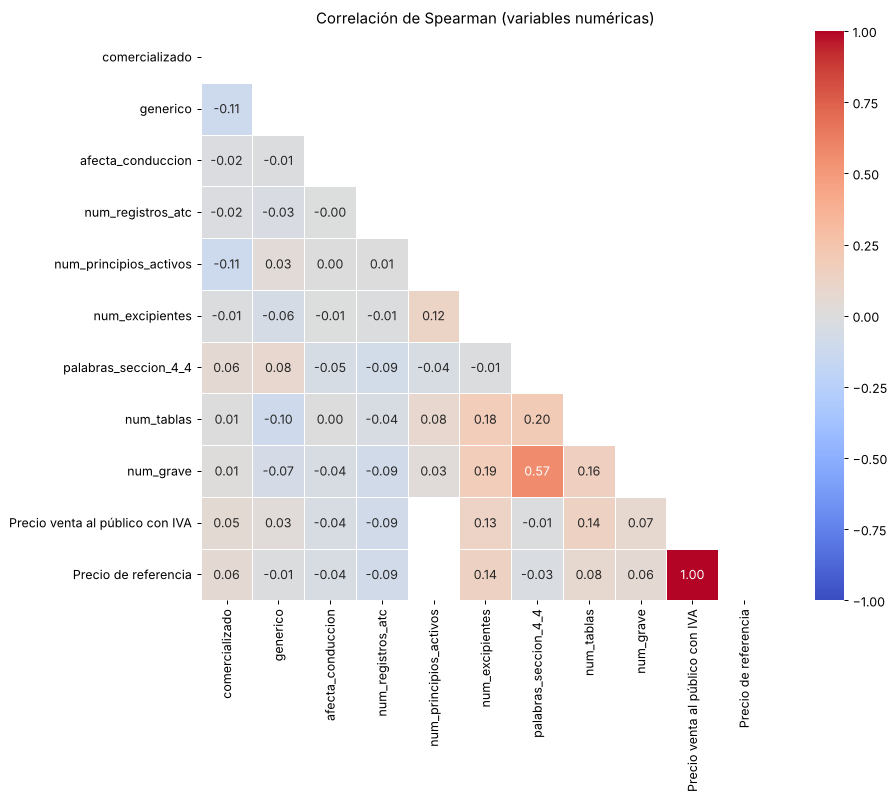

In [43]:
num = df_eda.select_dtypes("number").drop(columns=["nregistro", "cn"])
num = num.loc[:, num.nunique() > 1]          # quita las constantes (filas en blanco)

corr = num.corr(method="spearman")

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr,
    mask=np.triu(np.ones_like(corr, dtype=bool)),   # oculta la mitad repetida
    annot=True, fmt=".2f",
    cmap="coolwarm", center=0, vmin=-1, vmax=1,
    linewidths=0.5, square=True,
)
plt.title("Correlación de Spearman (variables numéricas)")
plt.tight_layout()
plt.show()

In [44]:
#comparamos con pearson las parejas que mas cambian
pearson=num.corr(method="pearson")
comparacion=pd.DataFrame({"pearson": pearson.stack(), "spearman": corr.stack()})
comparacion["diferencia"]=comparacion["spearman"]-comparacion["pearson"]
comparacion[comparacion["diferencia"].abs()>0.1].drop_duplicates("diferencia").round(2)

pearson  spearman  diferencia
generico               Precio venta al público con IVA    -0.19      0.03        0.22
                       Precio de referencia               -0.18     -0.01        0.17
num_principios_activos num_excipientes                     0.26      0.12       -0.14
num_excipientes        palabras_seccion_4_4               -0.12     -0.01        0.10
                       num_grave                           0.06      0.19        0.13
palabras_seccion_4_4   num_tablas                          0.03      0.20        0.16
                       num_grave                           0.74      0.57       -0.17
num_tablas             num_grave                           0.03      0.16        0.13

Usamos Spearman en vez de Pearson porque nuestras variables son asimétricas, tienen varios picos e incluyen binarias, y Pearson es muy sensible a los extremos. Al comparar los dos vemos que algunas correlaciones de Pearson estaban infladas por unos pocos medicamentos:
- PVP y precio de referencia: 1. Son la misma variable, nos quedamos solo con el PVP.
- `palabras_seccion_4_4` y `num_grave`: 0,57 (0,74 con Pearson). Es moderada y se explica por el principio activo (la quetiapina tiene mucho texto y muchos "grave").
- `generico` y precio: 0,03 (-0,19 con Pearson). No hay relación clara, la de Pearson la creaban unos pocos inyectables de marca muy caros.
- `num_principios_activos` y `num_excipientes`: 0,12 (0,26 con Pearson), solo por unos packs de paliperidona.

El resto de correlaciones son débiles, así que cada variable aporta información distinta, lo cual es bueno para el K-Means. Las variables constantes no se pueden correlacionar (salían como filas en blanco), por eso las quitamos del cálculo.

## 12. Resumen para la transformación

| Columna | Qué hacemos |
|---|---|
| `nregistro` | Se guarda para cruzar los clusters, no entra en el modelo |
| `cn`, `nombre`, `url_ficha_tecnica`, `url_foto_materiales` | Eliminar (después de quitar duplicados) |
| `requiere_receta`, `afecta_conduccion`, `medicamento_huerfano`, `biosimilar`, `triangulo_negro`, `num_principios_activos`, `num_registros_atc`, `Especial control médico` | Eliminar (constantes) |
| `estado_aut` | `antiguedad_anios` (fecha de referencia 27/09/2026) |
| `estado_rev` | `revocado` (0/1) |
| `Tratamiento de larga duración` | Nulos a UNKNOWN → `tld_unknown`, modelo con y sin ella |
| `Precio venta al público con IVA` | Rellenar con la mediana de principio activo + forma |
| `Precio de referencia` | Eliminar |
| `labcomercializador` | Rellenar con Zentiva K.S., OTROS con umbral 30 y one-hot |
| `labtitular` | Eliminar |
| `pactivos` | Unificar sales, OTROS con umbral 10 y one-hot |
| `dosis` | `dosis_mg` y `dosis_es_concentracion` |
| `forma_farmaceutica_simplificada`, `vias_administracion`, `Estado` | One-hot |
| `num_excipientes`, `palabras_seccion_4_4`, `num_tablas`, `num_grave`, `comercializado`, `generico` | Se quedan igual (los outliers no se tratan) |

Por último escalamos con `RobustScaler` y entrenamos dos versiones del K-Means, con y sin `tld_unknown`.

**Pendiente de decidir:** los packs de paliperidona en `dosis_mg`, si dejamos `comercializado` y `revocado` como dos variables o las juntamos en una, y si añadimos el código ATC de nivel 4.